# 02 · Decay curves and change-point detection
**Questions:** how fast does each format lose its CTR, and does a statistical method agree with our simple 25% fatigue rule?

## Part A · Decay curves
Each ad is normalised to its **own** peak, so a 2% ad and a 0.8% ad can be compared on one scale.

In [1]:
# cell 1: load
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"
df = pd.read_csv(ROOT / "data/processed/ad_daily_features.csv")

In [2]:
# cell 2: normalise every ad to its own peak
df["ctr_pct_of_peak"] = df["ctr_roll3"] / df.groupby("ad_id")["ctr_roll3"].transform("max") * 100

In [3]:
# cell 3: median curve per format, only where at least 5 ads have data
curve = (df[df["days_live"] <= 35]
         .groupby(["format", "days_live"])["ctr_pct_of_peak"]
         .agg(["median", "count"])
         .reset_index())
curve = curve[curve["count"] >= 5]

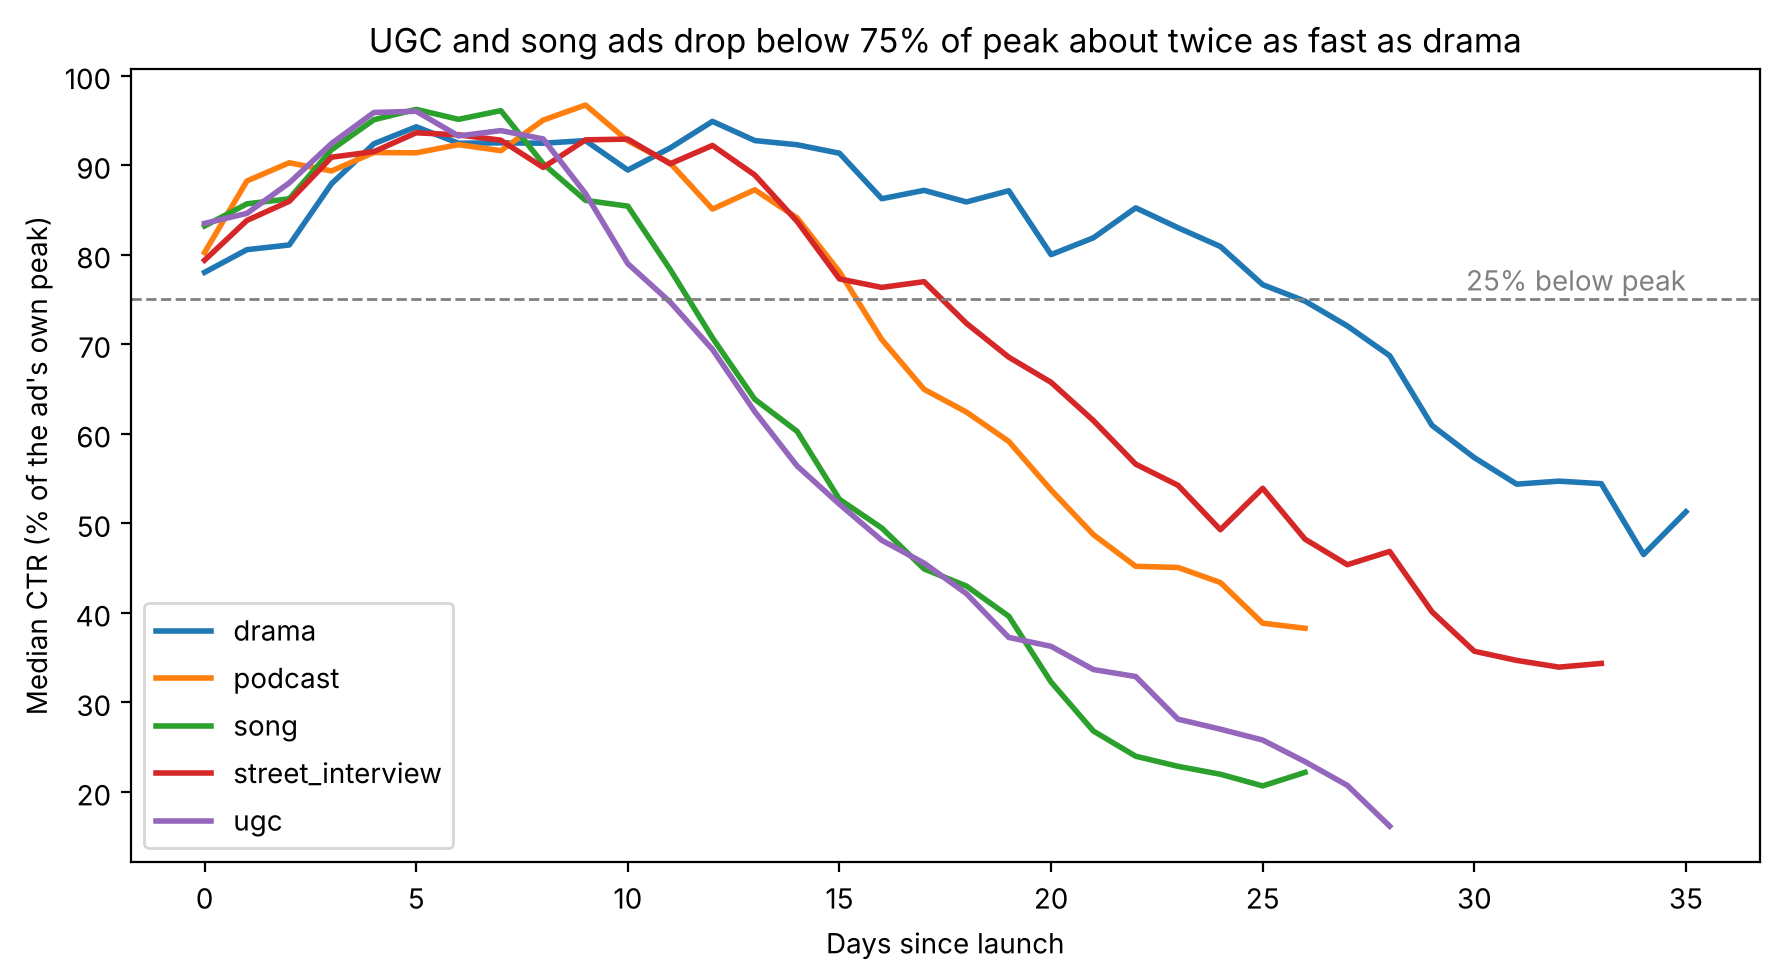

In [4]:
# cell 4: plot
fig, ax = plt.subplots(figsize=(9, 5))
for fmt, part in curve.groupby("format"):
    ax.plot(part["days_live"], part["median"], label=fmt, linewidth=2)
ax.axhline(75, color="grey", linestyle="--", linewidth=1)
ax.text(35, 76, "25% below peak", ha="right", color="grey")
ax.set_xlabel("Days since launch")
ax.set_ylabel("Median CTR (% of the ad's own peak)")
ax.set_title("UGC and song ads drop below 75% of peak about twice as fast as drama")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "decay_curves_by_format.png", dpi=150); plt.show()

In [5]:
# cell 5: first day each format's median falls below 75% of peak
curve[curve["median"] < 75].groupby("format")["days_live"].min().sort_values()

format
ugc                 11
song                12
podcast             16
street_interview    18
drama               26
Name: days_live, dtype: int64

**So what:** the median UGC ad falls below 75% of its peak by day 11, song by day 12, podcast by 16, street interview by 18 and drama by 26. UGC and song creatives burn out about twice as fast as drama.

*Caveat:* later days only include ads still running (paused ads drop out), so the right end of each curve rests on fewer ads. Notebook 03 handles this properly with survival analysis.

## Part B · Change-point detection (ruptures, PELT)
Find the day each ad's CTR shifts **down**, using statistics instead of a threshold.

In [6]:
# cell 1: load
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import ruptures as rpt

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"
df = pd.read_csv(ROOT / "data/processed/ad_daily_features.csv")
summary = pd.read_csv(ROOT / "data/processed/ad_summary.csv")

In [7]:
# cell 2: find the break day for one ad
def find_break_day(ad, penalty=3.0):
    """Return the days_live where CTR shifts DOWN, or None if there is no downward break."""
    signal = ad["ctr_pct"].to_numpy()
    if len(signal) < 8:
        return None
    signal = (signal - signal.mean()) / signal.std()        # put every ad on the same scale
    breaks = rpt.Pelt(model="l2", min_size=3).fit(signal).predict(pen=penalty)
    # predict() returns where each new segment starts; the last value is len(signal)
    edges = [0] + breaks
    for i in range(1, len(edges) - 1):
        before = signal[edges[i - 1]:edges[i]].mean()
        after = signal[edges[i]:edges[i + 1]].mean()
        if after < before:                                   # first downward shift
            return int(ad["days_live"].iloc[edges[i]])
    return None

In [8]:
# cell 3: run it for every ad
breaks = (df.sort_values(["ad_id", "date"])
            .groupby("ad_id")
            .apply(find_break_day, include_groups=False)
            .rename("break_day"))
summary = summary.merge(breaks, on="ad_id", how="left")
print("ads with a downward break:", summary["break_day"].notna().sum(), "of", len(summary))
summary.groupby("format")["break_day"].median().sort_values()

ads with a downward break: 102 of 114


format
ugc                 10.0
song                11.0
street_interview    15.0
podcast             15.0
drama               25.0
Name: break_day, dtype: float64

In [9]:
# cell 4: how close is the statistical break to the 25% rule?
both = summary.dropna(subset=["break_day", "onset_day"])
gap = both["onset_day"] - both["break_day"]
print(f"Rule onset comes a median of {gap.median():.0f} days after the break "
      f"(middle 50%: {gap.quantile(.25):.0f} to {gap.quantile(.75):.0f} days)")

Rule onset comes a median of 0 days after the break (middle 50%: -2 to 1 days)


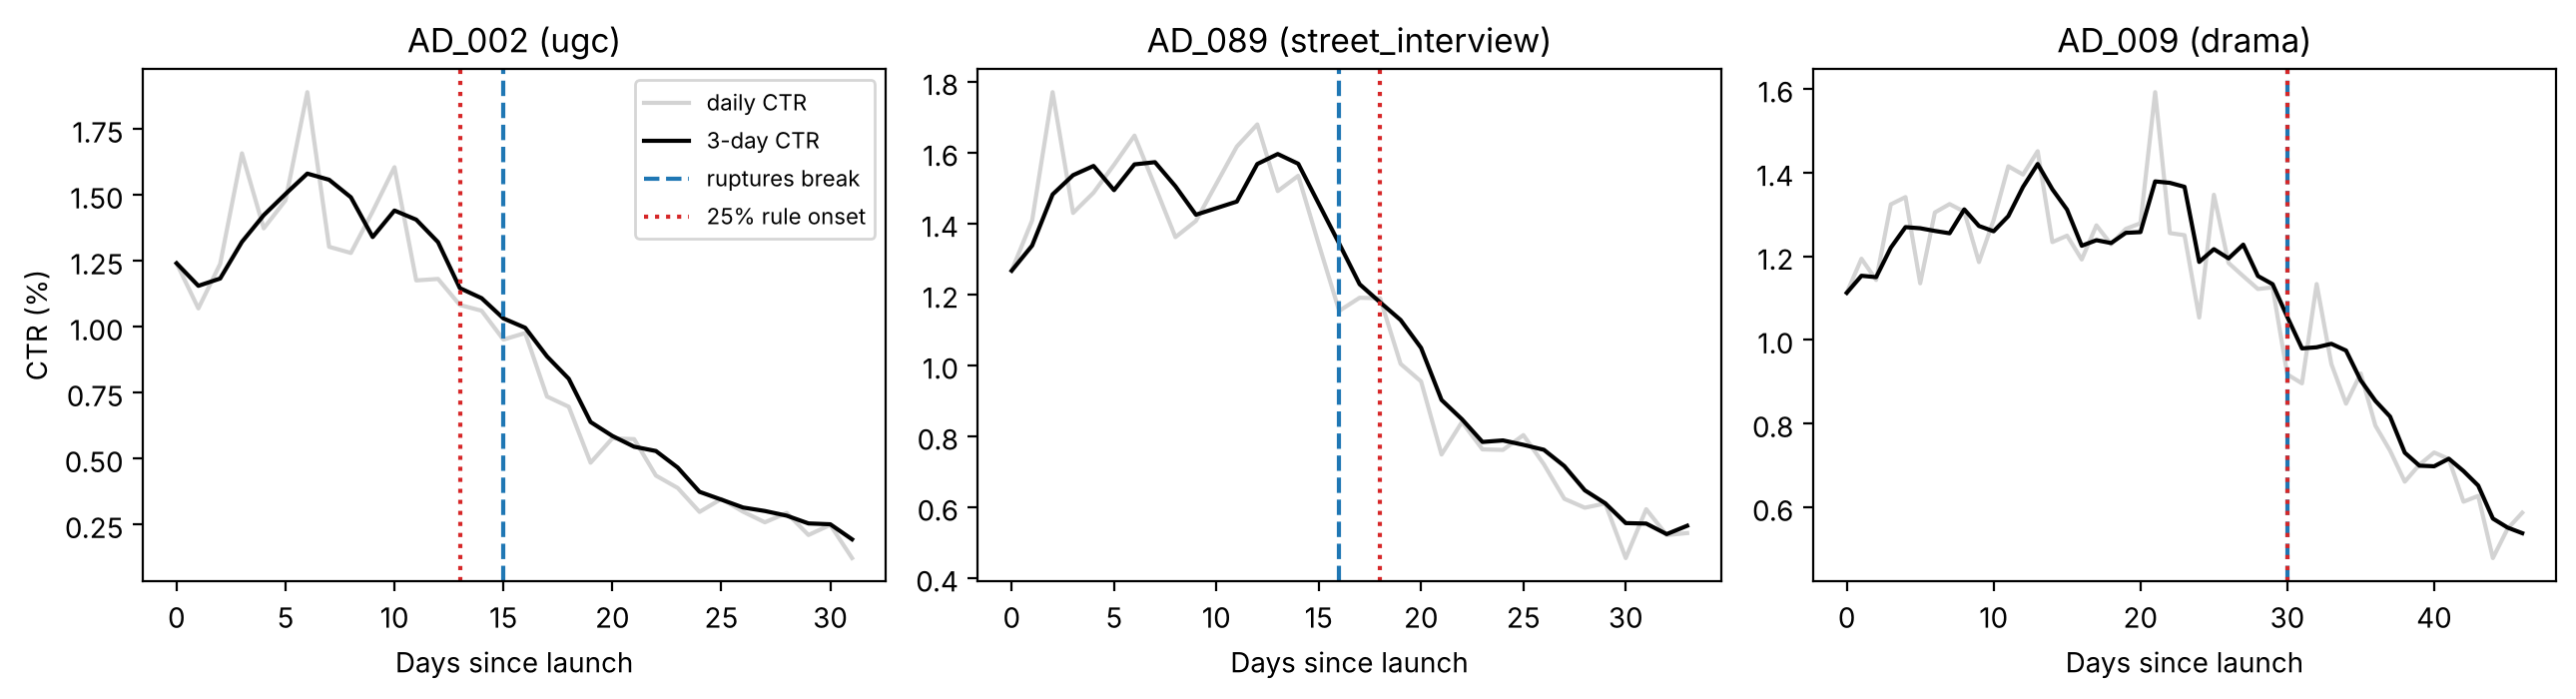

In [10]:
# cell 5: plot 3 example ads
examples = ["AD_002", "AD_089", "AD_009"]   # one UGC, one street interview, one drama
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, ad_id in zip(axes, examples):
    ad = df[df["ad_id"] == ad_id]
    row = summary.set_index("ad_id").loc[ad_id]
    ax.plot(ad["days_live"], ad["ctr_pct"], color="lightgrey", label="daily CTR")
    ax.plot(ad["days_live"], ad["ctr_roll3"], color="black", label="3-day CTR")
    if pd.notna(row["break_day"]):
        ax.axvline(row["break_day"], color="tab:blue", linestyle="--", label="ruptures break")
    if pd.notna(row["onset_day"]):
        ax.axvline(row["onset_day"], color="tab:red", linestyle=":", label="25% rule onset")
    ax.set_title(f"{ad_id} ({row['format']})"); ax.set_xlabel("Days since launch")
axes[0].set_ylabel("CTR (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "changepoint_examples.png", dpi=150); plt.show()

**So what:** 102 of 114 ads show a downward break. The 25% rule's onset lands a median of **0 days** from the statistical break (middle half: 2 days before to 1 day after). An independent method finds the same moment, so the simple rule is defensible.

*Choice tested:* the PELT penalty (`pen=3`). Lower values find more, smaller breaks; higher values find fewer.